In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt
from PIL import Image
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130


In [2]:

if torch.cuda.is_available():
    print("GPU is available!")
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available")


GPU is available!
GPU name: Tesla T4


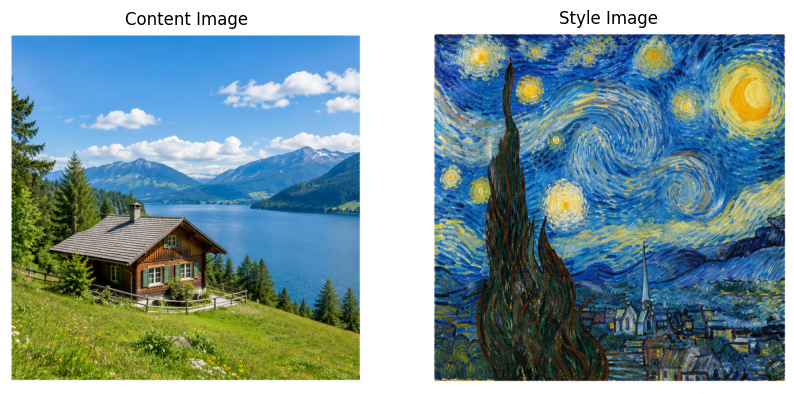

In [3]:

from PIL import Image
import matplotlib.pyplot as plt

content_image = Image.open(
    "/content/content_image (2).png"
).convert("RGB")

style_image = Image.open(
    "/content/style_image (1).png"
).convert("RGB")

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(content_image)
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(style_image)
plt.title("Style Image")
plt.axis("off")

plt.show()


In [4]:

image_size = 256

content_image = content_image.resize((image_size, image_size))
style_image = style_image.resize((image_size, image_size))

print("Content image size:", content_image.size)
print("Style image size:", style_image.size)


Content image size: (256, 256)
Style image size: (256, 256)


In [5]:

import torchvision.transforms as transforms


to_tensor = transforms.ToTensor()

content_tensor = to_tensor(content_image).unsqueeze(0)
style_tensor = to_tensor(style_image).unsqueeze(0)

print("Content tensor shape:", content_tensor.shape)
print("Style tensor shape:", style_tensor.shape)


Content tensor shape: torch.Size([1, 3, 256, 256])
Style tensor shape: torch.Size([1, 3, 256, 256])


In [6]:

import torch
import torchvision.models as models


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


weights = models.VGG19_Weights.DEFAULT
vgg = models.vgg19(weights=weights).features.to(device)


for parameter in vgg.parameters():
    parameter.requires_grad = False

vgg.eval()

print("VGG-19 loaded successfully!")
print("Device:", device)


Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:03<00:00, 178MB/s]


VGG-19 loaded successfully!
Device: cuda


In [7]:

from torchvision import transforms


normalise = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)


content_input = normalise(content_tensor.squeeze(0)).unsqueeze(0).to(device)
style_input = normalise(style_tensor.squeeze(0)).unsqueeze(0).to(device)

print("Content input shape:", content_input.shape)
print("Style input shape:", style_input.shape)
print("Images are ready for VGG-19!")


Content input shape: torch.Size([1, 3, 256, 256])
Style input shape: torch.Size([1, 3, 256, 256])
Images are ready for VGG-19!


In [8]:

def get_features(image, model):
    features = {}


    layer_names = {
        1: "conv1_1",
        6: "conv2_1",
        11: "conv3_1",
        20: "conv4_1",
        22: "conv4_2",
        29: "conv5_1"
    }

    x = image

    for index, layer in enumerate(model):
        x = layer(x)

        if index in layer_names:
            features[layer_names[index]] = x

    return features



content_features = get_features(content_input, vgg)
style_features = get_features(style_input, vgg)

print("Content feature shape:",
      content_features["conv4_2"].shape)

print("Style feature shape:",
      style_features["conv1_1"].shape)

print("Feature extraction successful!")


Content feature shape: torch.Size([1, 512, 32, 32])
Style feature shape: torch.Size([1, 64, 256, 256])
Feature extraction successful!


In [9]:

import torch

def content_loss(generated_features, target_features):
    return 0.5 * torch.sum(
        (generated_features - target_features) ** 2
    )



test_content_loss = content_loss(
    content_features["conv4_2"],
    content_features["conv4_2"]
)

print("Content loss for identical features:",
      test_content_loss.item())


Content loss for identical features: 0.0


In [10]:

def gram_matrix(features):
    batch_size, channels, height, width = features.shape


    features = features.view(
        batch_size, channels, height * width
    )


    gram = torch.bmm(features, features.transpose(1, 2))


    gram = gram / (channels * height * width)

    return gram



test_gram = gram_matrix(style_features["conv1_1"])

print("Gram matrix shape:", test_gram.shape)
print("Gram matrix created successfully!")


Gram matrix shape: torch.Size([1, 64, 64])
Gram matrix created successfully!


In [11]:

def style_loss(generated_features, target_features):
    generated_gram = gram_matrix(generated_features)
    target_gram = gram_matrix(target_features)

    return torch.mean(
        (generated_gram - target_gram) ** 2
    )



test_style_loss = style_loss(
    style_features["conv1_1"],
    style_features["conv1_1"]
)

print("Style loss for identical features:",
      test_style_loss.item())


Style loss for identical features: 0.0


**setting up the generated image** starting with the copy of the content image.

In [12]:


generated_image = content_tensor.clone().to(device)
generated_image.requires_grad_(True)

print("Generated image shape:", generated_image.shape)
print("Generated image can be optimised:",
      generated_image.requires_grad)


Generated image shape: torch.Size([1, 3, 256, 256])
Generated image can be optimised: True


**preparing the target features** we extracted the content and style features and now we will store them as fixed target for optimisation

In [13]:


style_layers = [
    "conv1_1",
    "conv2_1",
    "conv3_1",
    "conv4_1",
    "conv5_1"
]

content_layer = "conv4_2"

target_content = content_features[content_layer].detach()

target_style = {
    layer: style_features[layer].detach()
    for layer in style_layers
}

print("Content target prepared.")
print("Style targets prepared:", len(target_style))


Content target prepared.
Style targets prepared: 5


**Optimise the image**
 calculate the content loss and style loss for the generated image, combine them, and use Adam to update its pixels.

In [14]:

import torch
import torch.optim as optim
import matplotlib.pyplot as plt


mean = torch.tensor(
    [0.485, 0.456, 0.406], device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=device
).view(1, 3, 1, 1)

def normalise_for_vgg(image):
    return (image - mean) / std



optimizer = optim.Adam([generated_image], lr=0.03)

content_weight = 1.0
style_weight = 10000.0
num_steps = 150

loss_history = []

for step in range(num_steps):
    optimizer.zero_grad()


    generated_features = get_features(
        normalise_for_vgg(generated_image), vgg
    )


    c_loss = torch.mean(
        (generated_features[content_layer] - target_content) ** 2
    )


    s_loss = 0

    for layer in style_layers:
        s_loss = s_loss + style_loss(
            generated_features[layer],
            target_style[layer]
        )

    s_loss = s_loss / len(style_layers)


    total_loss = (
        content_weight * c_loss
        + style_weight * s_loss
    )


    total_loss.backward()
    optimizer.step()


    with torch.no_grad():
        generated_image.clamp_(0, 1)

    loss_history.append(total_loss.item())

    if (step + 1) % 25 == 0:
        print(
            f"Step {step + 1}/{num_steps} | "
            f"Content loss: {c_loss.item():.6f} | "
            f"Style loss: {s_loss.item():.8f} | "
            f"Total loss: {total_loss.item():.6f}"
        )

print("Image optimisation complete!")


Step 25/150 | Content loss: 0.463056 | Style loss: 0.00004294 | Total loss: 0.892478
Step 50/150 | Content loss: 0.199291 | Style loss: 0.00002533 | Total loss: 0.452639
Step 75/150 | Content loss: 0.143539 | Style loss: 0.00002197 | Total loss: 0.363189
Step 100/150 | Content loss: 0.121554 | Style loss: 0.00002079 | Total loss: 0.329474
Step 125/150 | Content loss: 0.111249 | Style loss: 0.00002008 | Total loss: 0.312005
Step 150/150 | Content loss: 0.108155 | Style loss: 0.00001953 | Total loss: 0.303420
Image optimisation complete!


**display generated image**

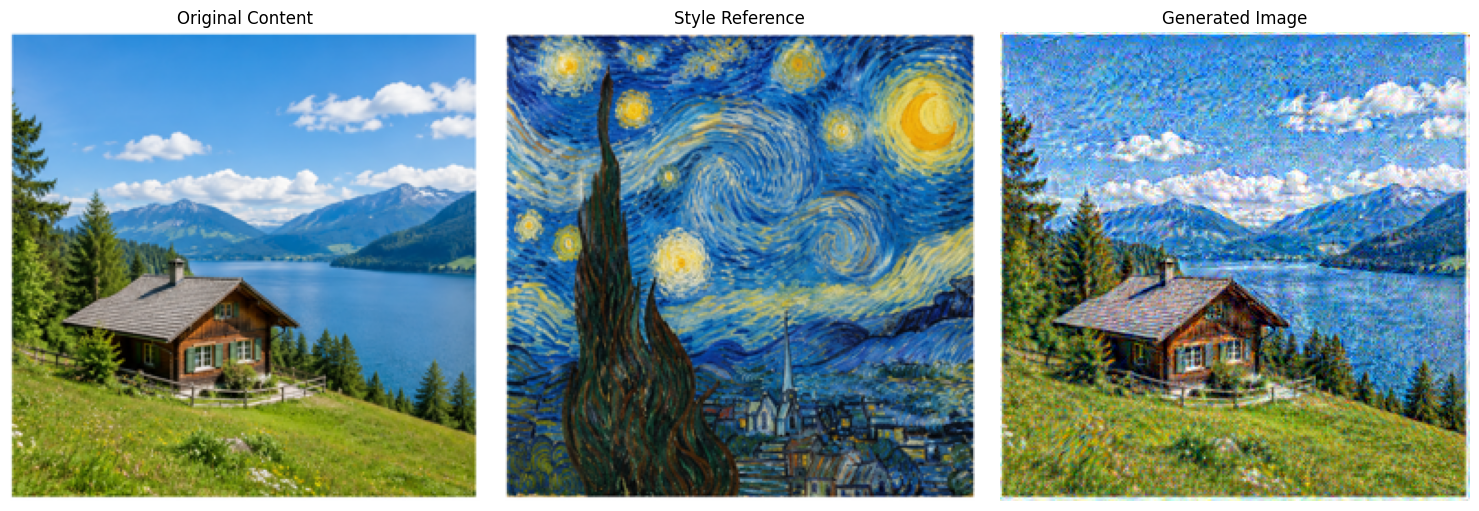

Saved: /content/generated_image.png


In [15]:


output = generated_image.detach().cpu().squeeze(0)
output = output.permute(1, 2, 0).numpy()


plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(content_image)
plt.title("Original Content")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(style_image)
plt.title("Style Reference")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(output)
plt.title("Generated Image")
plt.axis("off")

plt.tight_layout()
plt.show()


plt.imsave("/content/generated_image.png", output)

print("Saved: /content/generated_image.png")


**plotting the loss curve**

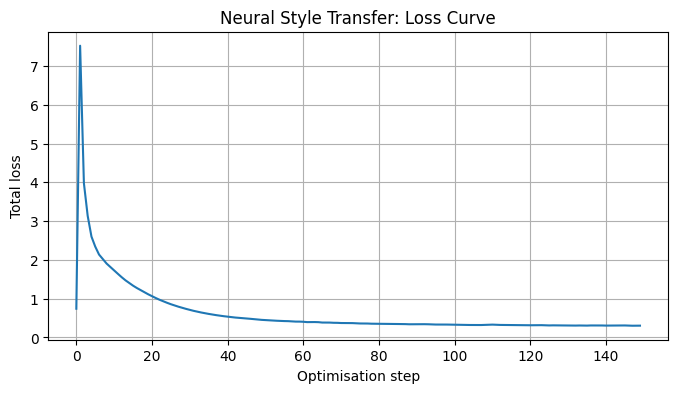

In [16]:

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Optimisation step")
plt.ylabel("Total loss")
plt.title("Neural Style Transfer: Loss Curve")
plt.grid(True)
plt.show()


**ablation experiment**

**baseline result** result against which all the coming experiments will be compared

In [17]:

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


os.makedirs("/content/style_transfer_results", exist_ok=True)


baseline_path = "/content/style_transfer_results/baseline.png"
plt.imsave(baseline_path, output)


plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Optimisation step")
plt.ylabel("Total loss")
plt.title("Baseline Loss Curve")
plt.grid(True)
plt.savefig(
    "/content/style_transfer_results/baseline_loss.png",
    dpi=150,
    bbox_inches="tight"
)
plt.close()

print("Baseline image and loss curve saved successfully.")


Baseline image and loss curve saved successfully.


**experiment 1** change style weight

In [18]:

def run_style_experiment(style_weight, steps=100):

    image = content_tensor.clone().to(device)
    image.requires_grad_(True)

    optimizer = optim.Adam([image], lr=0.03)
    history = []

    for step in range(steps):
        optimizer.zero_grad()

        features = get_features(
            normalise_for_vgg(image), vgg
        )


        c_loss = torch.mean(
            (features[content_layer] - target_content) ** 2
        )


        s_loss = 0

        for layer in style_layers:
            s_loss = s_loss + style_loss(
                features[layer], target_style[layer]
            )

        s_loss = s_loss / len(style_layers)


        total_loss = c_loss + style_weight * s_loss

        total_loss.backward()
        optimizer.step()

        with torch.no_grad():
            image.clamp_(0, 1)

        history.append(total_loss.item())

    result = image.detach().cpu().squeeze(0)
    result = result.permute(1, 2, 0).numpy()

    return result, history


print("Experiment function is ready!")


Experiment function is ready!


In [19]:

style_weights = [1000, 10000, 50000]

experiment_results = {}
experiment_histories = {}

for weight in style_weights:
    print("Running experiment with style weight:", weight)

    result, history = run_style_experiment(
        style_weight=weight,
        steps=100
    )

    experiment_results[weight] = result
    experiment_histories[weight] = history

    plt.imsave(
        f"/content/style_transfer_results/style_weight_{weight}.png",
        result
    )

print("All style-weight experiments completed!")


Running experiment with style weight: 1000
Running experiment with style weight: 10000
Running experiment with style weight: 50000
All style-weight experiments completed!


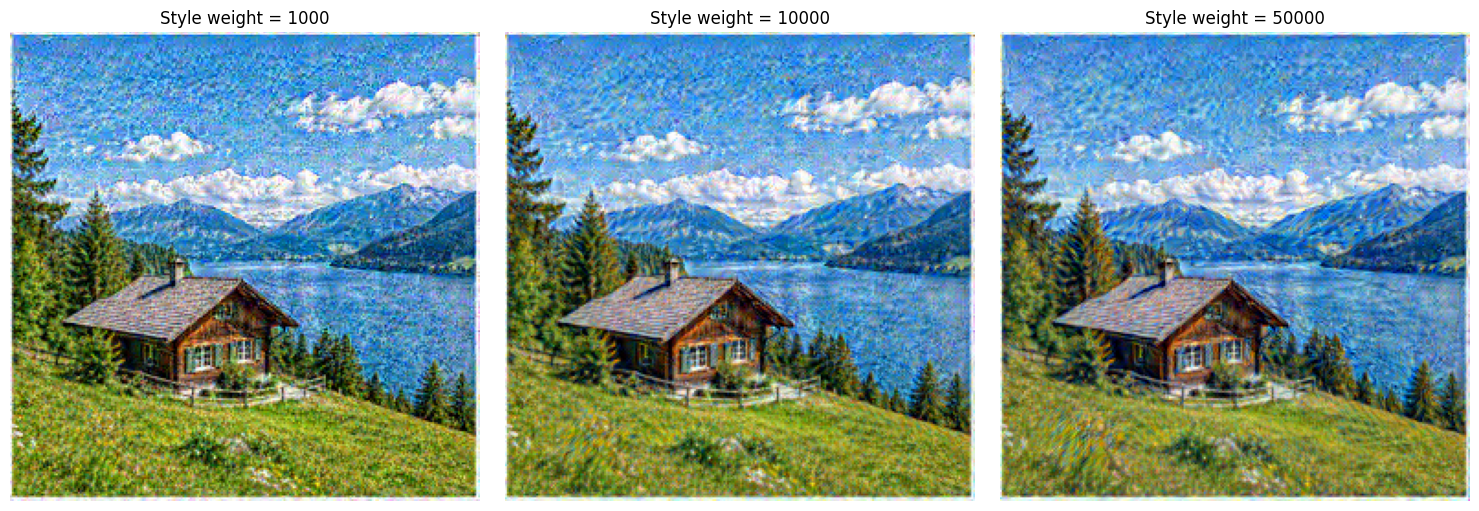

In [20]:

plt.figure(figsize=(15, 5))

for index, weight in enumerate(style_weights):
    plt.subplot(1, 3, index + 1)
    plt.imshow(experiment_results[weight])
    plt.title(f"Style weight = {weight}")
    plt.axis("off")

plt.tight_layout()
plt.show()


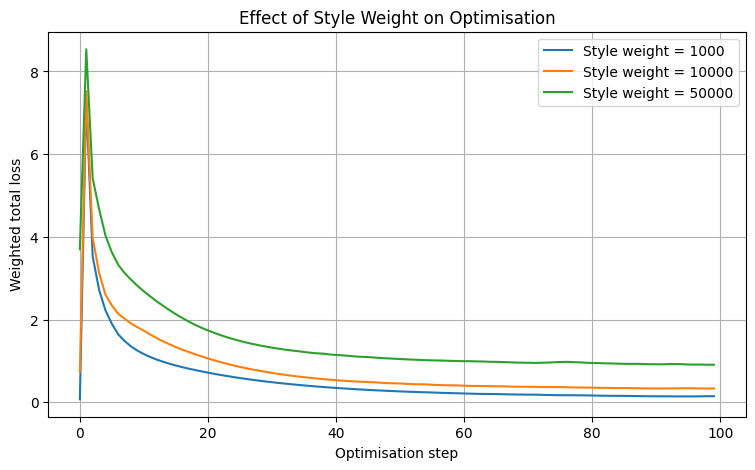

In [21]:

plt.figure(figsize=(9, 5))

for weight in style_weights:
    plt.plot(
        experiment_histories[weight],
        label=f"Style weight = {weight}"
    )

plt.xlabel("Optimisation step")
plt.ylabel("Weighted total loss")
plt.title("Effect of Style Weight on Optimisation")
plt.legend()
plt.grid(True)
plt.show()


their absolute values aren't directly comparable across different style weights. A larger weight changes the scale of the objective. The shape of each curve is useful for seeing how optimisation progresses.

**experiment 2** Change the style layers

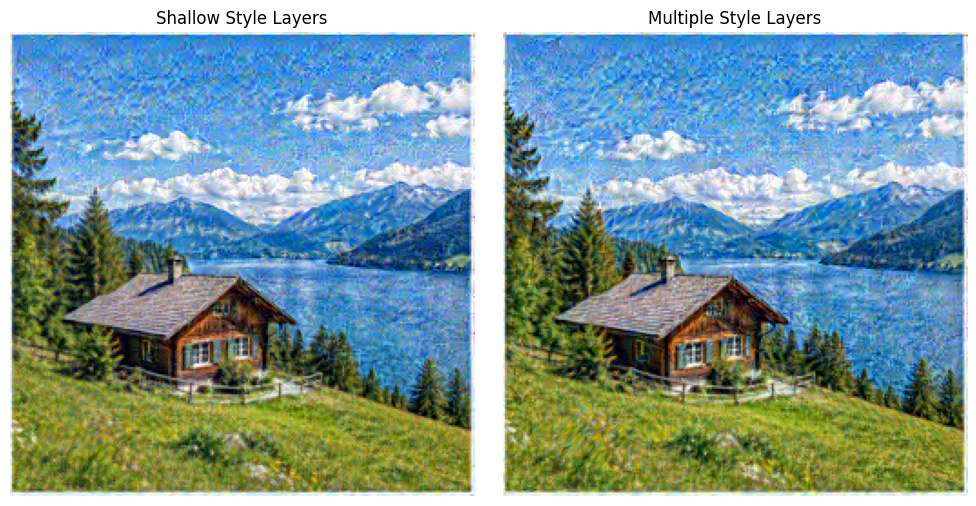

Layer comparison completed!


In [22]:

def run_layer_experiment(selected_layers, style_weight=10000, steps=100):
    image = content_tensor.clone().to(device)
    image.requires_grad_(True)

    optimizer = optim.Adam([image], lr=0.03)
    history = []

    for step in range(steps):
        optimizer.zero_grad()

        features = get_features(
            normalise_for_vgg(image), vgg
        )

        c_loss = torch.mean(
            (features[content_layer] - target_content) ** 2
        )

        s_loss = 0

        for layer in selected_layers:
            s_loss = s_loss + style_loss(
                features[layer], target_style[layer]
            )

        s_loss = s_loss / len(selected_layers)

        total_loss = c_loss + style_weight * s_loss
        total_loss.backward()
        optimizer.step()

        with torch.no_grad():
            image.clamp_(0, 1)

        history.append(total_loss.item())

    result = image.detach().cpu().squeeze(0)
    result = result.permute(1, 2, 0).numpy()

    return result, history


shallow_layers = ["conv1_1", "conv2_1"]

shallow_result, shallow_history = run_layer_experiment(
    shallow_layers
)

all_layers_result, all_layers_history = run_layer_experiment(
    style_layers
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(shallow_result)
plt.title("Shallow Style Layers")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(all_layers_result)
plt.title("Multiple Style Layers")
plt.axis("off")

plt.tight_layout()
plt.show()

plt.imsave(
    "/content/style_transfer_results/shallow_layers.png",
    shallow_result
)

plt.imsave(
    "/content/style_transfer_results/multiple_layers.png",
    all_layers_result
)

print("Layer comparison completed!")


The deeper-layer configuration may capture a broader range of patterns, but it doesn't guarantee a better image.

**OBSERVATIONS**


1.   style weight = 1000 : The landscape structure, including the house, mountains, lake, and trees, is preserved. Fine textures and colour variations are visible, but the overall style influence appears relatively subtle.

2.   style weight = 10,000 : The original landscape remains recognisable, with noticeable texture and colour variations across the sky, mountains, lake, and grass. It provides a balance between content preservation and style influence.

1.   Style weight = 50,000 : The main landscape structure is still preserved, while the output shows slightly stronger texture and colour patterns. However, the difference from the lower weights is not very large visually.

2.  Two shallow style layers (conv1_1, conv2_1) : The landscape structure remains clear. The output contains visible fine-grained textures and colour variations, with style patterns primarily influenced by lower-level visual features.

1.   Five style layers (conv1_1 to conv5_1, selected layers): The overall appearance is similar to the shallow-layer output. The image preserves the house, trees, mountains, and lake, with some differences in texture and detail from including deeper feature layers.








**experiment 1** increasing the style weight from 1,000 to 50,000 produces some changes in texture and colour patterns, although the differences are relatively subtle in the generated images

**experiment 2** Both shallow and multiple-layer configurations preserve the main landscape structure , multiple style layers does not necessarily produce a dramatically different result for every image.

Overall, the experiments illustrate the trade-off between content preservation and style representation.

In [23]:

import pandas as pd
import numpy as np
import torch

def evaluate_image(image_array, selected_layers, style_weight):

    image_tensor = torch.tensor(
        image_array, dtype=torch.float32
    ).permute(2, 0, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        features = get_features(
            normalise_for_vgg(image_tensor), vgg
        )


        c_loss = torch.mean(
            (features[content_layer] - target_content) ** 2
        )


        s_loss = 0

        for layer in selected_layers:
            s_loss += style_loss(
                features[layer], target_style[layer]
            )

        s_loss = s_loss / len(selected_layers)

        total = c_loss + style_weight * s_loss

    return (
        c_loss.item(),
        s_loss.item(),
        total.item()
    )



rows = []

for weight in style_weights:
    c, s, total = evaluate_image(
        experiment_results[weight],
        style_layers,
        weight
    )

    rows.append({
        "Experiment": f"Style weight {weight}",
        "Content Loss": c,
        "Style Loss": s,
        "Weighted Total Loss": total
    })

for name, image_array, layers in [
    ("Shallow layers", shallow_result, shallow_layers),
    ("Multiple layers", all_layers_result, style_layers)
]:
    c, s, total = evaluate_image(
        image_array, layers, 10000
    )

    rows.append({
        "Experiment": name,
        "Content Loss": c,
        "Style Loss": s,
        "Weighted Total Loss": total
    })

results_df = pd.DataFrame(rows)

display(results_df.round(8))


,Experiment,Content Loss,Style Loss,Weighted Total Loss
0,Style weight 1000,0.098070,0.000046,0.144174
1,Style weight 10000,0.126294,0.000021,0.331838
2,Style weight 50000,0.260563,0.000013,0.910853
3,Shallow layers,0.077248,0.000003,0.110212
4,Multiple layers,0.133304,0.000020,0.338028


In [24]:

results_df.to_csv(
    "/content/style_transfer_results/experiment_metrics.csv",
    index=False
)

print("Experiment metrics saved successfully!")


Experiment metrics saved successfully!


In [25]:

import os
import zipfile


plt.imsave(
    "/content/style_transfer_results/baseline.png",
    output
)

zip_path = "/content/style_transfer_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(
        "/content/style_transfer_results"
    ):
        for file in files:
            full_path = os.path.join(root, file)
            relative_path = os.path.relpath(
                full_path, "/content"
            )
            zipf.write(full_path, relative_path)

print("All experiment results packaged successfully!")
print("ZIP location:", zip_path)


All experiment results packaged successfully!
ZIP location: /content/style_transfer_results.zip


In [26]:

from google.colab import files

files.download("/content/style_transfer_results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>